# Crack the latent baseline

**Target**: beat `heavy_spike_only_within_p8` (within-only) on spatial R².
**Starting point**: `heavy_spike_spike_dom_p8` (cross-modal, same encoder).

Experiments vary **projection head** and **proj_dim** — the hypothesis being that a non-linear head
lets alignment happen in projection space while keeping the encoder embeddings spatially organised.

Evaluation: **Z_spike**, **Z_lfp**, and **Z_concat** R² reported separately every eval.

In [1]:
import pickle, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

import sys
for _p in [Path('.'), *Path('.').resolve().parents]:
    if (_p / 'comets' / '__init__.py').exists():
        if str(_p) not in sys.path: sys.path.insert(0, str(_p))
        break
from comets import (
    ModalityConfig, SamplingConfig, LatentTrainingConfig,
    CEBRASKipEncoder, SkippedConvEncoderConfig,
    LinearHead, OneLayerMLP, TwoLayerMLP,
    train_latent,
)

ROOT     = Path('.').resolve()
DATA_DIR = '/mnt/d/comets/data/crcns_mouse'
SESSION  = 'ec013.156'

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

def _style_map(styler, fn, **kw):
    try: return styler.map(fn, **kw)
    except AttributeError: return styler.applymap(fn, **kw)

print('Setup OK')

Setup OK


In [2]:
data = pickle.load(open(f'{DATA_DIR}/{SESSION}/{SESSION}_lfp_spike.pkl', 'rb'))
lfp        = np.asarray(data['lfp_theta_50hz'], dtype=np.float32)
spike_rate = np.asarray(data['spike_rate'],     dtype=np.float32)
position   = np.asarray(data['position_50hz'],  dtype=np.float64)
if position.ndim == 2: position = position[:, 0]

rmin, rmax = spike_rate.min(0, keepdims=True), spike_rate.max(0, keepdims=True)
spike_norm = (spike_rate - rmin) / (rmax - rmin + 1e-9)

T, N = spike_norm.shape
C    = lfp.shape[1]
print(f'Session {SESSION}:  T={T}  N={N} neurons  C={C} LFP channels')

Session ec013.156:  T=51179  N=83 neurons  C=64 LFP channels


In [3]:
def window_kfold_r2(Z, pos=position, win_size=10, n_folds=10, alpha=1.0):
    Z   = np.asarray(Z,   dtype=np.float64)
    pos = np.asarray(pos, dtype=np.float64)
    T_  = min(len(Z), len(pos))
    nw  = T_ // win_size
    Z_w = Z[:nw*win_size].reshape(nw, win_size, -1).mean(1)
    y_w = pos[:nw*win_size].reshape(nw, win_size).mean(1)
    fs  = nw // n_folds;  n = fs * n_folds
    Z_w, y_w = Z_w[:n], y_w[:n]
    r2s = []
    for k in range(n_folds):
        mask = np.zeros(n, dtype=bool);  mask[k*fs:(k+1)*fs] = True
        reg = Ridge(alpha=alpha).fit(Z_w[~mask], y_w[~mask])
        r2s.append(float(r2_score(y_w[mask], reg.predict(Z_w[mask]))))
    return float(np.mean(r2s))

def eval_embeddings(Z_spk, Z_lf):
    """Returns dict: r2_spike, r2_lfp, r2_concat."""
    return dict(
        r2_spike  = window_kfold_r2(Z_spk),
        r2_lfp    = window_kfold_r2(Z_lf),
        r2_concat = window_kfold_r2(np.concatenate([Z_spk, Z_lf], axis=1)),
    )

print('Eval helpers ready.')

Eval helpers ready.


---
## Baselines (loaded from grid runs, no retraining)

In [4]:
def load_run(run_name, ckp='best'):
    d = ROOT / 'runs' / 'latent' / run_name / SESSION
    Z_spk = np.load(d / f'Z_spikes_{ckp}.npy')
    Z_lf  = np.load(d / f'Z_lfp_{ckp}.npy')
    return eval_embeddings(Z_spk, Z_lf)

SCORES = {}
SCORES['only_within (target)'] = load_run('heavy_spike_only_within_p8')
SCORES['spike_dom  (start)']   = load_run('heavy_spike_spike_dom_p8')

TARGET = SCORES['only_within (target)']['r2_concat']   # the number to beat

for name, s in SCORES.items():
    print(f'{name:30s}  spike={s["r2_spike"]:+.4f}  lfp={s["r2_lfp"]:+.4f}  concat={s["r2_concat"]:+.4f}')

only_within (target)            spike=+0.5675  lfp=-0.0934  concat=+0.5836
spike_dom  (start)              spike=+0.5273  lfp=+0.1207  concat=+0.5447


---
## quick_train

In [5]:
def quick_train(
    label,
    alpha_cross = 0.1,
    beta        = 0.95,
    head_cls    = TwoLayerMLP,   # LinearHead | OneLayerMLP | TwoLayerMLP
    proj_dim    = 8,
    temperature = 1.0,
    epochs      = 200,
    eval_every  = 20,
    lr          = 1e-3,
    batch_size  = 256,
    # encoder — defaults to heavy_spike (matches grid baseline)
    emb_A=32, hidden_A=64, blocks_A=4, win_A=8,
    emb_B=16, hidden_B=32, blocks_B=2, win_B=8,
):
    modA = ModalityConfig(CEBRASKipEncoder,
                          SkippedConvEncoderConfig(N, emb_A, hidden_A, blocks_A), win_len=win_A)
    modB = ModalityConfig(CEBRASKipEncoder,
                          SkippedConvEncoderConfig(C, emb_B, hidden_B, blocks_B), win_len=win_B)
    sampling = SamplingConfig(batch_size=batch_size, pos_offset=5, negative_mask_dist=16)
    cfg      = LatentTrainingConfig(
        epochs=epochs, lr=lr, temperature=temperature,
        proj_dim=proj_dim, alpha_cross=alpha_cross,
        beta=beta, head_cls=head_cls,
    )

    log = dict(epoch=[], r2_spike=[], r2_lfp=[], r2_concat=[])

    def cb(ep, model):
        Z_s = model.embed_latent_spikes(spike_norm)
        Z_l = model.embed_latent_lfp(lfp)
        s = eval_embeddings(Z_s, Z_l)
        for k in log: log[k].append(ep if k=='epoch' else s[k])
        beat = ' ← BEAT!' if s['r2_concat'] > TARGET else ''
        print(f'  ep {ep:3d}  spike={s["r2_spike"]:+.4f}  lfp={s["r2_lfp"]:+.4f}  concat={s["r2_concat"]:+.4f}{beat}')

    model = train_latent(spike_norm, modA, lfp, modB, sampling, cfg,
                         epoch_callback=cb, eval_every=eval_every)

    Z_spk = model.embed_latent_spikes(spike_norm)
    Z_lf  = model.embed_latent_lfp(lfp)
    scores = eval_embeddings(Z_spk, Z_lf)
    SCORES[label] = scores

    fig, axes = plt.subplots(1, 3, figsize=(13, 3))
    for ax, key, color in [
        (axes[0], 'r2_spike',  'tab:blue'),
        (axes[1], 'r2_lfp',    'tab:green'),
        (axes[2], 'r2_concat', 'tab:orange'),
    ]:
        ax.plot(log['epoch'], log[key], color=color, lw=1.5)
        ax.axhline(SCORES['only_within (target)'][key], color='gray', ls='--', lw=1, label='only_within')
        ax.axhline(SCORES['spike_dom  (start)'][key],  color='salmon', ls=':', lw=1, label='spike_dom')
        ax.set(xlabel='Epoch', title=key); ax.legend(fontsize=7); ax.grid(alpha=0.3)
    fig.suptitle(label, fontweight='bold'); plt.tight_layout(); plt.show()

    print(f'  FINAL  spike={scores["r2_spike"]:+.4f}  lfp={scores["r2_lfp"]:+.4f}  concat={scores["r2_concat"]:+.4f}  (Δ concat vs only_within: {scores["r2_concat"]-TARGET:+.4f})')
    return model, scores

print('quick_train ready.')

quick_train ready.


---
## Experiments — spike_dom + head / proj_dim variations

Fixed: `heavy_spike` encoder, `alpha_cross=0.1`, `beta=0.95`.  
Varied: `head_cls`, `proj_dim`, `temperature`.

Stage 1: Latent Encoder:   6%|▌         | 11/200 [00:30<48:30, 15.40s/it, total=4.7908, within=4.7577, cross=5.0890, lr=9.76e-04]   

  ep  20  spike=+0.5201  lfp=+0.0981  concat=+0.5322


Stage 1: Latent Encoder:  15%|█▌        | 30/200 [00:59<14:12,  5.02s/it, total=4.7446, within=4.7129, cross=5.0300, lr=9.05e-04]

  ep  40  spike=+0.4798  lfp=+0.2263  concat=+0.5039


Stage 1: Latent Encoder:  24%|██▍       | 49/200 [01:28<06:46,  2.69s/it, total=4.7186, within=4.6889, cross=4.9855, lr=7.94e-04]

  ep  60  spike=+0.4903  lfp=+0.2327  concat=+0.4955


... (10 outputs left out)

Stage 1: Latent Encoder:  72%|███████▎  | 145/200 [04:23<01:32,  1.68s/it, total=4.6828, within=4.6622, cross=4.8675, lr=2.45e-05]

  ep 180  spike=+0.4646  lfp=+0.3954  concat=+0.4827


Stage 1: Latent Encoder: 100%|██████████| 200/200 [04:50<00:00,  1.45s/it, total=4.6821, within=4.6619, cross=4.8643, lr=0.00e+00]


  ep 200  spike=+0.4652  lfp=+0.3957  concat=+0.4826


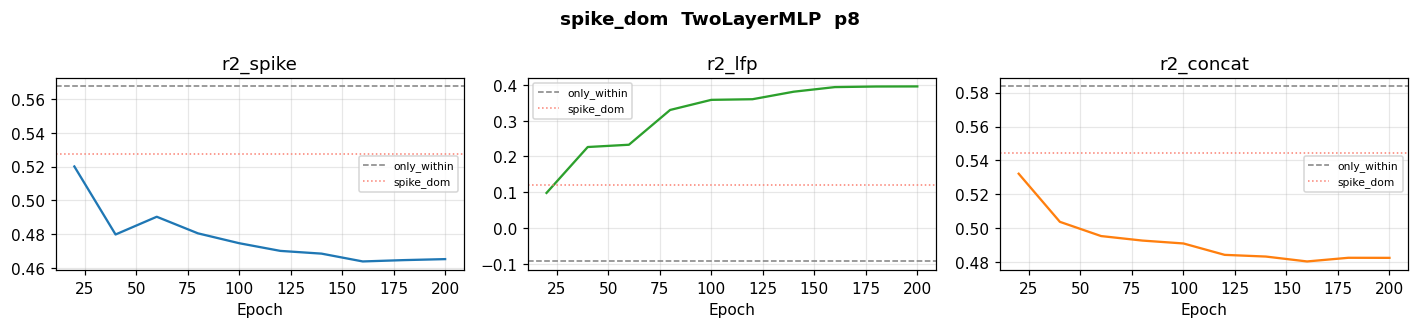

  FINAL  spike=+0.4652  lfp=+0.3957  concat=+0.4826  (Δ concat vs only_within: -0.1010)


In [6]:
# TwoLayerMLP head, proj_dim=8  (same dim as grid, different head)
model_1, s1 = quick_train('spike_dom  TwoLayerMLP  p8',
    head_cls=TwoLayerMLP, proj_dim=8)

Stage 1: Latent Encoder:  10%|█         | 20/200 [00:29<04:38,  1.55s/it, total=4.7769, within=4.7437, cross=5.0754, lr=9.76e-04]

  ep  20  spike=+0.5539  lfp=+0.1120  concat=+0.5632


Stage 1: Latent Encoder:  18%|█▊        | 35/200 [00:59<2:58:35, 64.94s/it, total=4.7333, within=4.7025, cross=5.0105, lr=9.05e-04]

  ep  40  spike=+0.5162  lfp=+0.2282  concat=+0.5196


Stage 1: Latent Encoder:  24%|██▍       | 49/200 [01:28<11:39,  4.63s/it, total=4.7039, within=4.6736, cross=4.9770, lr=7.94e-04]  

  ep  60  spike=+0.5066  lfp=+0.3238  concat=+0.5071


... (10 outputs left out)

Stage 1: Latent Encoder:  71%|███████   | 142/200 [04:23<01:26,  1.48s/it, total=4.6683, within=4.6450, cross=4.8785, lr=2.45e-05]

  ep 180  spike=+0.4759  lfp=+0.3982  concat=+0.4771


Stage 1: Latent Encoder: 100%|██████████| 200/200 [04:52<00:00,  1.46s/it, total=4.6677, within=4.6445, cross=4.8764, lr=0.00e+00]


  ep 200  spike=+0.4759  lfp=+0.4017  concat=+0.4776


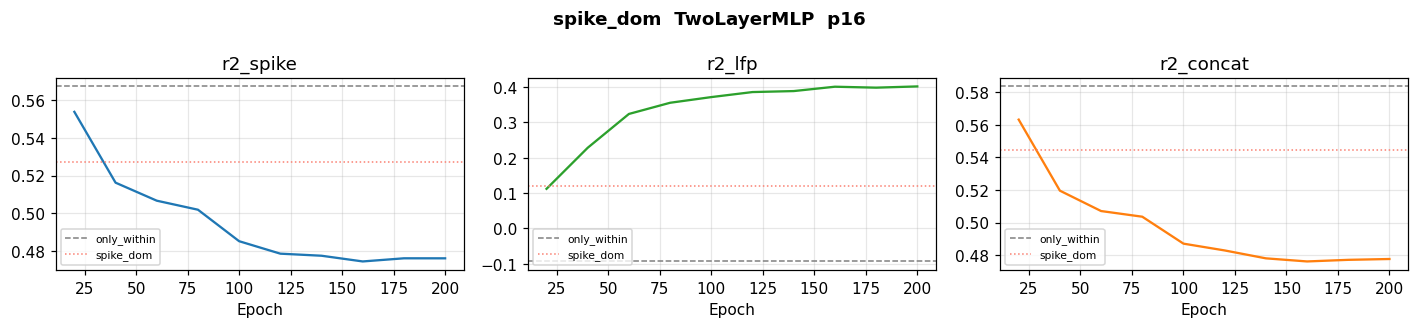

  FINAL  spike=+0.4759  lfp=+0.4017  concat=+0.4776  (Δ concat vs only_within: -0.1060)


In [7]:
# TwoLayerMLP head, proj_dim=16
model_2, s2 = quick_train('spike_dom  TwoLayerMLP  p16',
    head_cls=TwoLayerMLP, proj_dim=16)

Stage 1: Latent Encoder:  10%|█         | 20/200 [04:01<3:15:01, 65.01s/it, total=4.7614, within=4.7278, cross=5.0634, lr=9.76e-04]

  ep  20  spike=+0.6287  lfp=+0.1936  concat=+0.6365 ← BEAT!


Stage 1: Latent Encoder:  10%|█         | 20/200 [00:57<3:15:01, 65.01s/it, total=4.7207, within=4.6887, cross=5.0084, lr=9.05e-04]

  ep  40  spike=+0.6118  lfp=+0.3181  concat=+0.6203 ← BEAT!


Stage 1: Latent Encoder:  10%|█         | 20/200 [01:27<3:15:01, 65.01s/it, total=4.6949, within=4.6641, cross=4.9721, lr=7.94e-04]

  ep  60  spike=+0.5936  lfp=+0.3410  concat=+0.6059 ← BEAT!


... (10 outputs left out)

Stage 1: Latent Encoder:  90%|█████████ | 180/200 [07:51<00:28,  1.44s/it, total=4.6519, within=4.6258, cross=4.8860, lr=2.45e-05]

  ep 180  spike=+0.6139  lfp=+0.4952  concat=+0.6124 ← BEAT!


Stage 1: Latent Encoder: 100%|██████████| 200/200 [04:47<00:00,  1.44s/it, total=4.6514, within=4.6257, cross=4.8829, lr=0.00e+00]


  ep 200  spike=+0.6136  lfp=+0.4973  concat=+0.6126 ← BEAT!


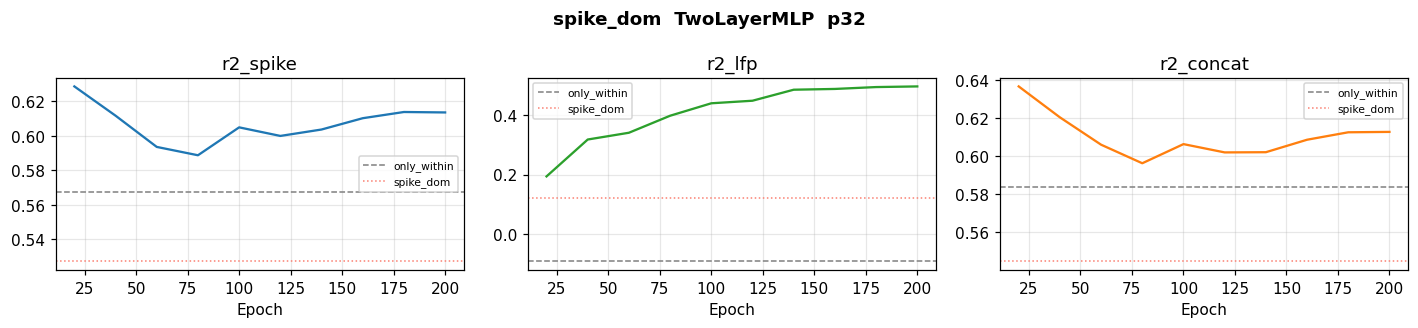

  FINAL  spike=+0.6136  lfp=+0.4973  concat=+0.6126  (Δ concat vs only_within: +0.0290)


In [8]:
# TwoLayerMLP head, proj_dim=32
model_3, s3 = quick_train('spike_dom  TwoLayerMLP  p32',
    head_cls=TwoLayerMLP, proj_dim=32)

Stage 1: Latent Encoder:   6%|▋         | 13/200 [00:27<3:23:57, 65.44s/it, total=4.8614, within=4.8217, cross=5.2184, lr=9.76e-04]

  ep  20  spike=+0.4862  lfp=-0.0865  concat=+0.4960


Stage 1: Latent Encoder:   6%|▋         | 13/200 [00:56<3:23:57, 65.44s/it, total=4.8201, within=4.7791, cross=5.1889, lr=9.05e-04]

  ep  40  spike=+0.4911  lfp=-0.0631  concat=+0.4994


Stage 1: Latent Encoder:  28%|██▊       | 55/200 [01:25<10:25,  4.31s/it, total=4.7882, within=4.7485, cross=5.1446, lr=7.94e-04]  

  ep  60  spike=+0.4805  lfp=-0.0024  concat=+0.4869


... (10 outputs left out)

Stage 1: Latent Encoder:  73%|███████▎  | 146/200 [04:20<01:28,  1.63s/it, total=4.7346, within=4.6998, cross=5.0478, lr=2.45e-05]

  ep 180  spike=+0.4474  lfp=+0.1466  concat=+0.4567


Stage 1: Latent Encoder: 100%|██████████| 200/200 [04:50<00:00,  1.45s/it, total=4.7327, within=4.6982, cross=5.0431, lr=0.00e+00]


  ep 200  spike=+0.4479  lfp=+0.1502  concat=+0.4575


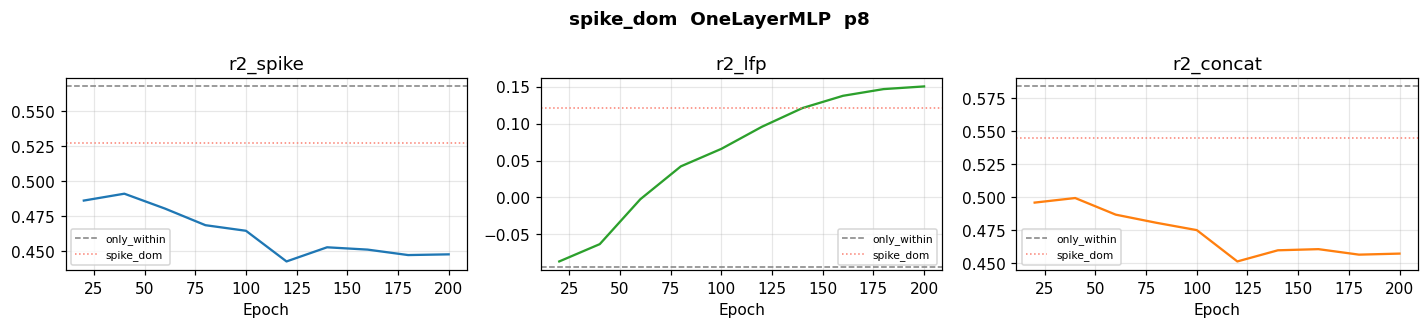

  FINAL  spike=+0.4479  lfp=+0.1502  concat=+0.4575  (Δ concat vs only_within: -0.1262)


In [9]:
# OneLayerMLP head, proj_dim=8
model_4, s4 = quick_train('spike_dom  OneLayerMLP  p8',
    head_cls=OneLayerMLP, proj_dim=8)

Stage 1: Latent Encoder:   6%|▌         | 11/200 [00:30<3:28:42, 66.26s/it, total=4.2115, within=4.1423, cross=4.8348, lr=9.76e-04]

  ep  20  spike=+0.4438  lfp=+0.0833  concat=+0.4782


Stage 1: Latent Encoder:   6%|▌         | 11/200 [00:59<3:28:42, 66.26s/it, total=4.1122, within=4.0457, cross=4.7109, lr=9.05e-04]

  ep  40  spike=+0.4255  lfp=+0.2492  concat=+0.4547


Stage 1: Latent Encoder:   6%|▌         | 11/200 [01:29<3:28:42, 66.26s/it, total=4.0506, within=3.9840, cross=4.6499, lr=7.94e-04]

  ep  60  spike=+0.3799  lfp=+0.2837  concat=+0.4089


... (10 outputs left out)

Stage 1: Latent Encoder:  74%|███████▎  | 147/200 [04:28<02:16,  2.58s/it, total=3.9683, within=3.9142, cross=4.4549, lr=2.45e-05]

  ep 180  spike=+0.3575  lfp=+0.3760  concat=+0.4035


Stage 1: Latent Encoder: 100%|██████████| 200/200 [04:58<00:00,  1.49s/it, total=3.9676, within=3.9133, cross=4.4563, lr=0.00e+00]


  ep 200  spike=+0.3585  lfp=+0.3777  concat=+0.4043


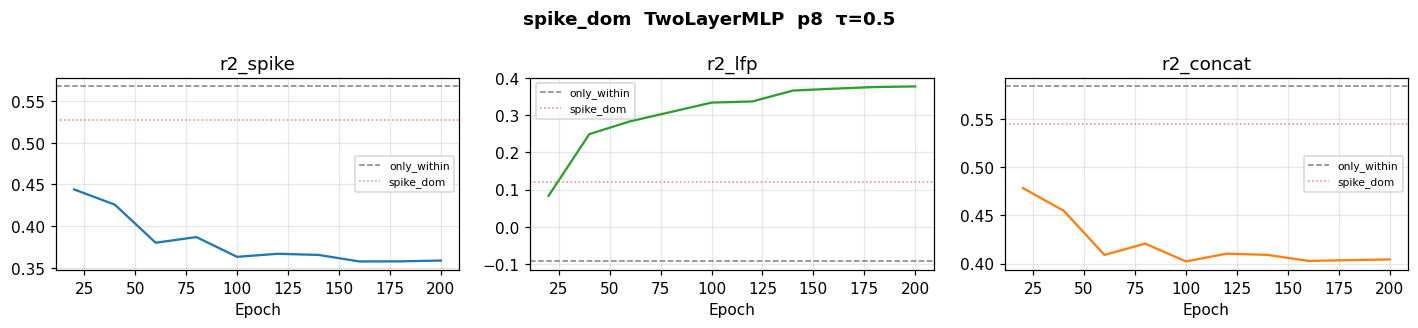

  FINAL  spike=+0.3585  lfp=+0.3777  concat=+0.4043  (Δ concat vs only_within: -0.1794)


In [10]:
# TwoLayerMLP, sharper temperature
model_5, s5 = quick_train('spike_dom  TwoLayerMLP  p8  τ=0.5',
    head_cls=TwoLayerMLP, proj_dim=8, temperature=0.5)

Stage 1: Latent Encoder:  10%|█         | 20/200 [00:29<04:21,  1.45s/it, total=4.7746, within=4.7403, cross=5.0838, lr=9.76e-04]

  ep  20  spike=+0.5620  lfp=+0.1079  concat=+0.5885 ← BEAT!


Stage 1: Latent Encoder:  20%|██        | 40/200 [00:57<03:48,  1.43s/it, total=4.7363, within=4.7046, cross=5.0215, lr=9.05e-04]

  ep  40  spike=+0.5268  lfp=+0.2351  concat=+0.5465


Stage 1: Latent Encoder:  30%|███       | 60/200 [01:27<03:26,  1.47s/it, total=4.7114, within=4.6808, cross=4.9869, lr=7.94e-04]

  ep  60  spike=+0.4729  lfp=+0.2621  concat=+0.4869


... (10 outputs left out)

Stage 1: Latent Encoder:  82%|████████▏ | 163/200 [04:17<01:42,  2.77s/it, total=4.6785, within=4.6532, cross=4.9060, lr=2.45e-05]

  ep 180  spike=+0.4180  lfp=+0.3523  concat=+0.4359


Stage 1: Latent Encoder: 100%|██████████| 200/200 [04:47<00:00,  1.44s/it, total=4.6781, within=4.6527, cross=4.9069, lr=0.00e+00]


  ep 200  spike=+0.4173  lfp=+0.3515  concat=+0.4350


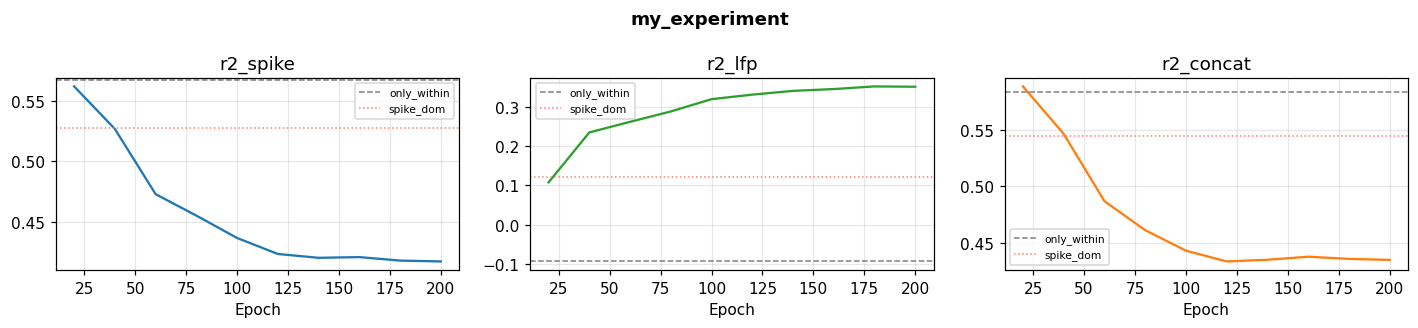

  FINAL  spike=+0.4173  lfp=+0.3515  concat=+0.4350  (Δ concat vs only_within: -0.1486)


In [11]:
# Free cell — your config here
model_X, sX = quick_train('my_experiment',
    head_cls=LinearHead, proj_dim=16,
    alpha_cross=0.1, beta=0.95,
)

---
## Summary table

In [12]:
df = pd.DataFrame(SCORES).T
target_row = SCORES['only_within (target)']

def color(val, col):
    base = target_row[col]
    d = val - base
    if d > 0.005:  return 'background-color: rgba(0,180,0,0.4)'
    if d < -0.005: return 'background-color: rgba(200,0,0,0.25)'
    return ''

s = df.style.format('{:+.4f}')
for col in df.columns:
    s = _style_map(s, lambda v, c=col: color(v, c), subset=[col])
display(s.set_caption('Green = beats only_within baseline on that metric'))

,r2_spike,r2_lfp,r2_concat
only_within (target),+0.5675,-0.0934,+0.5836
spike_dom (start),+0.5273,+0.1207,+0.5447
spike_dom TwoLayerMLP p8,+0.4652,+0.3957,+0.4826
spike_dom TwoLayerMLP p16,+0.4759,+0.4017,+0.4776
spike_dom TwoLayerMLP p32,+0.6136,+0.4973,+0.6126
spike_dom OneLayerMLP p8,+0.4479,+0.1502,+0.4575
spike_dom TwoLayerMLP p8 τ=0.5,+0.3585,+0.3777,+0.4043
my_experiment,+0.4173,+0.3515,+0.4350


---
## Unit embedding (optional — run after finding a winning latent config)

Uncomment and set `WINNING_MODEL` to the model you want to evaluate.

In [14]:
WINNING_MODEL = model_1   # <-- set to whichever model won
EMBEDDING_LABEL = 'spike_dom TwoLayerMLP p32'

import pickle as _pkl
from scipy.ndimage import gaussian_filter1d
from comets import train_unit, UnitTrainingConfig, SamplingConfig as SC
from comets.unit_eval import ratemap_correlation

spike_count = np.asarray(
    _pkl.load(open(f'{DATA_DIR}/{SESSION}/{SESSION}_lfp_spike.pkl','rb'))['spike_bin'],
    dtype=np.float32)

Z_spk_win = WINNING_MODEL.embed_latent_spikes(spike_norm)
Z_lf_win  = WINNING_MODEL.embed_latent_lfp(lfp)

# ratemaps
edges    = np.linspace(position.min(), position.max(), 41)
pos_bins = np.clip(np.digitize(position, edges)-1, 0, 39)
fs       = float(data['fs_common'])
occ      = np.bincount(pos_bins, minlength=40) / fs
rm = np.zeros((spike_count.shape[1], 40), dtype=np.float32)
for i in range(spike_count.shape[1]):
    rm[i] = np.bincount(pos_bins, weights=spike_count[:,i], minlength=40) / (occ+1e-9)
from scipy.ndimage import gaussian_filter1d
rm = gaussian_filter1d(rm, sigma=2.0, axis=1)

unit_enc = train_unit(None, spike_count, SC(batch_size=256),
                      UnitTrainingConfig(epochs=200, d_u=8, lambda_coact=0.25, lambda_ctx=0.75),
                      z_spikes=Z_spk_win, z_lfp=Z_lf_win)
rho, _ = ratemap_correlation(unit_enc.embeddings().numpy(), rm)
print(f'{EMBEDDING_LABEL}  rho_ratemap = {rho:+.4f}')

Stage 2: Unit Encoder: 100%|██████████| 200/200 [02:15<00:00,  1.47it/s, loss=-2.9076, lr=0.00e+00] 

spike_dom TwoLayerMLP p32  rho_ratemap = +0.6212
